In [7]:
%pip install --upgrade pip

     |████████████████████████████████| 2.1MB 9.3MB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --retries 10 --timeout 300 --no-cache-dir --index-url https://pypi.org/simple pandas==1.3.5 numpy==1.21.6 matplotlib==3.5.3 seaborn==0.12.2 scikit-learn==1.0.2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.5/138.5 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 10.7 MB/s eta 0:00:000:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 11.5 MB/s eta 0:00:00m eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 478.0 kB/s eta 0:00:000:00:01m eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 293.3/293.3 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.8/24.8 MB 3.6 MB/s eta 0:00:00m eta 0:00:010:01:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 965.4/965.4 kB 12.1 MB/s eta 0:00:0031m12.1 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.2/302.2 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.2 MB/s eta 0:00:00 MB/s eta 0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.5/53.5 kB 75.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 1.8 MB/s eta 0:00:00 MB/s

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
df = pd.read_csv("emails.csv")

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

First five rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Dataset shape: (5172, 3002)

Column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', '

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate records, if any
df = df.drop_duplicates().copy()

# Replace infinite values and handle missing values
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna().copy()

print("\nShape after cleaning:", df.shape)
display(df.head())

Missing values: 0
Duplicate rows: 0

Shape after cleaning: (5172, 3002)


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [4]:
# Identify the target column
target_col = "Prediction" if "Prediction" in df.columns else df.columns[-1]

# Remove the email identifier from the features
X = df.drop(columns=[target_col])
X = X.select_dtypes(include=np.number)

if "Email No." in X.columns:
    X = X.drop(columns=["Email No."])

# Target variable
y = df[target_col].astype(int)

print("Target column:", target_col)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nClass distribution in percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Target column: Prediction
Feature shape: (5172, 3000)
Target shape: (5172,)

Class distribution:
0    3672
1    1500
Name: Prediction, dtype: int64

Class distribution in percentage:
0    71.0
1    29.0
Name: Prediction, dtype: float64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 4137
Testing samples: 1035
Number of features: 3000


In [8]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("KNN model trained successfully!")
print("KNN Accuracy:", round(
    accuracy_score(y_test, y_pred_knn) * 100, 2
), "%")

KNN model trained successfully!
KNN Accuracy: 83.38 %


In [9]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM model trained successfully!")
print("SVM Accuracy:", round(
    accuracy_score(y_test, y_pred_svm) * 100, 2
), "%")

SVM model trained successfully!
SVM Accuracy: 93.14 %


In [10]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_true, y_pred, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_true, y_pred, zero_division=0) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(y_true, y_pred, zero_division=0) * 100, 2
        )
    }

results = pd.DataFrame([
    evaluate_model("KNN", y_test, y_pred_knn),
    evaluate_model("SVM", y_test, y_pred_svm)
])

display(results)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,KNN,83.38,64.35,95.67,76.94
1,SVM,93.14,83.78,94.67,88.89


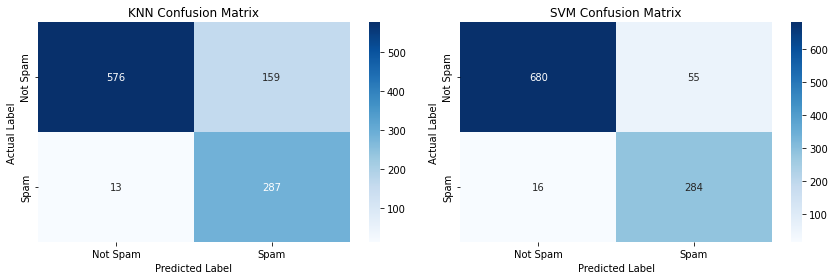

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

predictions = [
    ("KNN", y_pred_knn),
    ("SVM", y_pred_svm)
]

for ax, (name, prediction) in zip(axes, predictions):
    cm = confusion_matrix(y_test, prediction, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [12]:
print("KNN Classification Report")
print(classification_report(
    y_test,
    y_pred_knn,
    labels=[0, 1],
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

print("\nSVM Classification Report")
print(classification_report(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

KNN Classification Report
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


SVM Classification Report
              precision    recall  f1-score   support

    Not Spam       0.98      0.93      0.95       735
        Spam       0.84      0.95      0.89       300

    accuracy                           0.93      1035
   macro avg       0.91      0.94      0.92      1035
weighted avg       0.94      0.93      0.93      1035



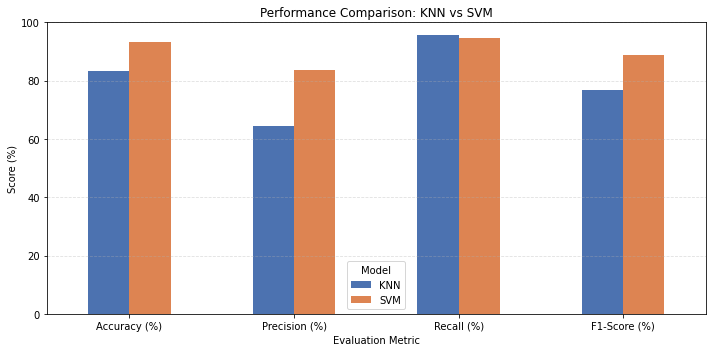

In [13]:
metrics_to_plot = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

results_plot = results.set_index("Model")[metrics_to_plot]

results_plot.T.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 100),
    color=["#4C72B0", "#DD8452"]
)

plt.title("Performance Comparison: KNN vs SVM")
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [14]:
best_model = results.loc[
    results["F1-Score (%)"].idxmax(), "Model"
]

print("Performance comparison:")
display(results)

print("Best model based on F1-score:", best_model)

Performance comparison:


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,KNN,83.38,64.35,95.67,76.94
1,SVM,93.14,83.78,94.67,88.89


Best model based on F1-score: SVM
